               AgriForecast – Agricultural Sales Forecasting Using Machine   
               `Learning` **bold text**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

### Interpretation
This step provides additional information about the dataset needed for the EDA process and helps verify the structure or values before continuing with further analysis.

In [ ]:
import pandas as pd

df = pd.read_csv("/content/AgricultureData.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 8893
Columns: 10


Interpretation: The dataset contains records organized into rows and variables organized into columns.
The number of rows indicates the number of records, while the number of columns indicates the number of features available for analysis.")
```

In [ ]:
# Load the Kaggle agricultural sales dataset
import os
import pandas as pd

csv_path = "/content/AgricultureData.csv"

if not os.path.exists(csv_path):
    from google.colab import files
    print("Upload the CSV downloaded from the Kaggle dataset page.")
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No CSV file was uploaded.")
    csv_path = next(iter(uploaded.keys()))

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("File:", os.path.basename(csv_path))
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
File: AgricultureData.csv
Shape: (8893, 10)


,product_id,product_name,category,price_per_kg,units_shipped_kg,units_sold_kg,units_on_hand_kg,supplier,farm_location,sale_date
0,b12c721e-8301-4b08-8ac3-d435be9b8b32,Lamb,Livestock,14.10,19224,14905,4319,Organic Meats Co.,"O'Reillyboro, OR",2022-07-04
1,4a0f8862-c851-4073-bc17-3a3d93834902,Beef,Livestock,11.37,29504,4550,24954,Organic Meats Co.,"Lake Nora, AR",2023-10-21
2,be996df6-1780-4352-8b7d-1f927279aa49,Oranges,Fruits,2.59,1838,1722,116,Berry Fields,"East Friedaside, NM",2023-12-24
3,6c8adfc3-2114-4b78-a3e2-2269a6a0dc02,Milk,Dairy,1.34,6750,1232,5518,Fresh Dairy Farms,"East Javon, FL",2023-12-25
4,0bd5bf2b-be0a-4ba0-aa92-059021b169e3,Bananas,Fruits,1.78,48729,47020,1709,Golden Orchards,"Lake D'angelo, MN",2023-06-20


### Interpretation – Dataset Loading

This cell loads the CSV downloaded from the specified Kaggle dataset and displays its actual dimensions and first five records. Use the printed shape and column names from your run in the final report; do not rely on hard-coded counts.


## Data Quality Gate – Validate the Target and Key Fields

Before modeling, verify the required columns, target validity, date parsing, negative values, and the exact relationship between sales, shipment, and stock. These checks help catch schema changes or unexpected dataset versions early.


In [ ]:
required_columns = ["sale_date", "units_sold_kg"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns missing from CSV: {missing_required}. Available columns: {df.columns.tolist()}")

print("Null counts:")
display(df.isna().sum().to_frame("null_count"))

print("Blank-string counts:")
blank_counts = df.select_dtypes(include="object").apply(lambda col: col.astype(str).str.strip().eq("").sum())
display(blank_counts.to_frame("blank_count"))

for col in ["units_sold_kg", "units_shipped_kg", "units_on_hand_kg", "price_per_kg"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "sale_date" in df.columns:
    parsed_dates = pd.to_datetime(df["sale_date"], errors="coerce")
    print("Unparseable sale_date rows:", int(parsed_dates.isna().sum()))

if "units_sold_kg" in df.columns:
    print("Negative target rows:", int((df["units_sold_kg"] < 0).sum()))
    print("Zero target rows:", int((df["units_sold_kg"] == 0).sum()))

if {"units_shipped_kg", "units_sold_kg", "units_on_hand_kg"}.issubset(df.columns):
    relationship_ok = np.isclose(
        df["units_shipped_kg"] - df["units_sold_kg"],
        df["units_on_hand_kg"], equal_nan=False
    )
    print("Rows matching shipped - sold = on-hand:", int(relationship_ok.sum()), "/", len(df))


Null counts:


,null_count
product_id,0
product_name,0
category,0
price_per_kg,0
units_shipped_kg,0
units_sold_kg,0
units_on_hand_kg,0
supplier,0
farm_location,0
sale_date,0


Blank-string counts:


,blank_count
product_id,0
product_name,0
category,0
supplier,0
farm_location,0
sale_date,0


Unparseable sale_date rows: 0
Negative target rows: 0
Zero target rows: 1
Rows matching shipped - sold = on-hand: 8893 / 8893


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 8893
Number of Columns: 10


### Interpretation – Dataset Dimensions
The dataset has **8,893 observations** and **10 variables**. This provides a sufficient number of records for exploratory analysis and supervised machine learning.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8893 entries, 0 to 8892
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_id        8893 non-null   object 
 1   product_name      8893 non-null   object 
 2   category          8893 non-null   object 
 3   price_per_kg      8893 non-null   float64
 4   units_shipped_kg  8893 non-null   int64  
 5   units_sold_kg     8893 non-null   int64  
 6   units_on_hand_kg  8893 non-null   int64  
 7   supplier          8893 non-null   object 
 8   farm_location     8893 non-null   object 
 9   sale_date         8893 non-null   object 
dtypes: float64(1), int64(3), object(6)
memory usage: 694.9+ KB


### Interpretation – Data Types and Structure
This step checks the structure and data types of all columns. The dataset contains numerical, categorical, identifier, and date-related information. Correct data types are important before performing EDA and machine learning.

In [ ]:
df.describe()

,price_per_kg,units_shipped_kg,units_sold_kg,units_on_hand_kg
count,8893.000000,8893.000000,8893.000000,8893.000000
mean,3.641478,25471.785562,12545.278421,12926.507140
std,3.306348,14177.334372,10772.529049,10996.124845
min,0.400000,1005.000000,0.000000,0.000000
25%,0.970000,13228.000000,3642.000000,3890.000000
50%,2.680000,25468.000000,9643.000000,9805.000000
75%,5.300000,37964.000000,18832.000000,19622.000000
max,14.390000,50000.000000,49726.000000,49818.000000


### Interpretation – Numerical Summary

Use the output of `describe()` to discuss the target's central tendency, spread, minimum, and maximum. Check for unexpected negative values, implausible quantities, and strong skew. Report the actual values printed by your run rather than copying example numbers.


In [ ]:
df.describe(include="object")

,product_id,product_name,category,supplier,farm_location,sale_date
count,8893,8893,8893,8893,8893,8893
unique,28,28,5,20,8862,730
top,57ad2178-9598-4981-b0f7-78a91162821e,Cheese,Fruits,Citrus World Inc.,"Mayertberg, VT",2022-04-07
freq,464,464,1846,492,2,24


### Interpretation – Categorical Summary

Use `describe(include="object")` and the unique-count output to understand category diversity. A column with many unique values, such as a location identifier, can create a high-dimensional encoded feature space and should be considered carefully during modeling.


In [ ]:
missing_values = df.isnull().sum()

print(missing_values)

product_id          0
product_name        0
category            0
price_per_kg        0
units_shipped_kg    0
units_sold_kg       0
units_on_hand_kg    0
supplier            0
farm_location       0
sale_date           0
dtype: int64


### Interpretation – Missing Values

The table above reports the actual missing-value count for each column. If any values are missing, decide how to handle them using training data only for model preprocessing. A zero count means no explicit nulls were found, but blank strings and invalid date/numeric values should still be checked separately.


In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_percentage

,0
product_id,0.0
product_name,0.0
category,0.0
price_per_kg,0.0
units_shipped_kg,0.0
units_sold_kg,0.0
units_on_hand_kg,0.0
supplier,0.0
farm_location,0.0
sale_date,0.0


### Interpretation – Missing Percentage

This output expresses missing values as a percentage of rows. Use the observed results to describe which columns need attention. Also check blank strings and conversion failures, because `isnull()` alone does not detect every data-quality issue.


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


### Interpretation – Duplicate Records

The output shows the number of fully duplicated rows. If duplicates exist, inspect them before removing them: identical-looking rows may be valid repeated transactions depending on how the dataset was collected.


In [ ]:
for column in df.columns:
    print(
        column,
        ":",
        df[column].nunique(),
        "unique values"
    )

product_id : 28 unique values
product_name : 28 unique values
category : 5 unique values
price_per_kg : 1256 unique values
units_shipped_kg : 8143 unique values
units_sold_kg : 7630 unique values
units_on_hand_kg : 7632 unique values
supplier : 20 unique values
farm_location : 8862 unique values
sale_date : 730 unique values


### Interpretation – Unique Value Counts
This code counts the number of unique values in each column. It helps identify categorical variables, understand their cardinality, and detect high-cardinality columns that may require special handling.

In [ ]:
print("Products:", df["product_name"].nunique())
print("Categories:", df["category"].nunique())
print("Suppliers:", df["supplier"].nunique())
print("Farm Locations:", df["farm_location"].nunique())

Products: 28
Categories: 5
Suppliers: 20
Farm Locations: 8862


### Interpretation – Unique Categories
The dataset contains **28 products, 5 categories, 20 suppliers, and 8,862 farm locations**. The farm-location column is almost unique for every record, so using it directly may add noise and increase model complexity.

In [ ]:
df.dtypes

,0
product_id,object
product_name,object
category,object
price_per_kg,float64
units_shipped_kg,int64
units_sold_kg,int64
units_on_hand_kg,int64
supplier,object
farm_location,object
sale_date,object


### Interpretation – Data Types
This output confirms the data types of the variables. Numerical columns can be used for numerical analysis, categorical columns require encoding for ML, and `sale_date` needs to be converted to a proper datetime format.

In [ ]:
df["sale_date"] = pd.to_datetime(
    df["sale_date"],
    errors="coerce"
)

df.dtypes

,0
product_id,object
product_name,object
category,object
price_per_kg,float64
units_shipped_kg,int64
units_sold_kg,int64
units_on_hand_kg,int64
supplier,object
farm_location,object
sale_date,datetime64[ns]


### Interpretation – Date Conversion
The `sale_date` column is converted to datetime format successfully. This allows us to extract useful time-based features such as year, month, day, quarter, day of week, and weekend status.

In [ ]:
df["units_sold_kg"].describe()

,units_sold_kg
count,8893.000000
mean,12545.278421
std,10772.529049
min,0.000000
25%,3642.000000
50%,9643.000000
75%,18832.000000
max,49726.000000


### Interpretation – Target Variable
The target `units_sold_kg` has a mean of **12,545.28 kg**, median of **9,643 kg**, minimum of **0 kg**, and maximum of **49,726 kg**. The mean being higher than the median indicates a right-skewed distribution, with some observations having relatively high sales.

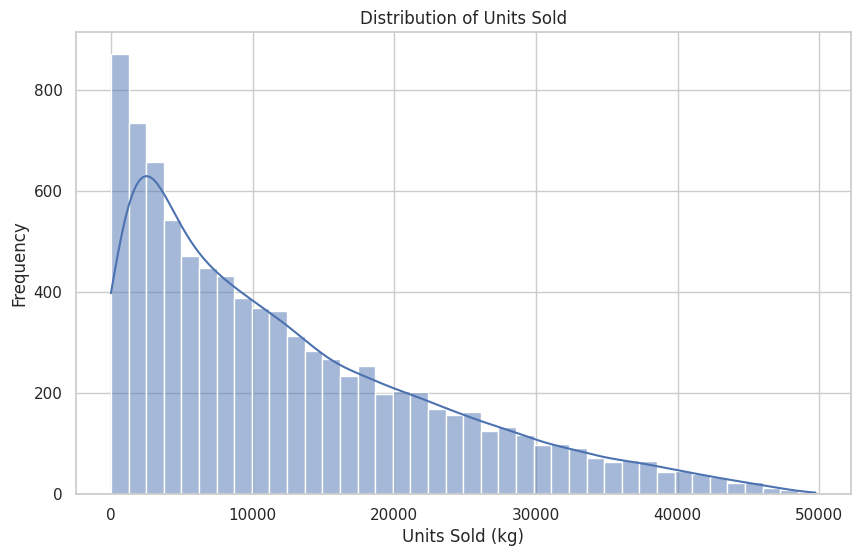

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["units_sold_kg"],
    bins=40,
    kde=True
)

plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold (kg)")
plt.ylabel("Frequency")

plt.show()

### Interpretation – Units Sold Distribution
The histogram shows the distribution of the target variable `units_sold_kg`. Most observations are concentrated at lower and medium sales levels, while a smaller number of observations extend toward higher sales values. This helps identify the overall shape and spread of the target before model building.

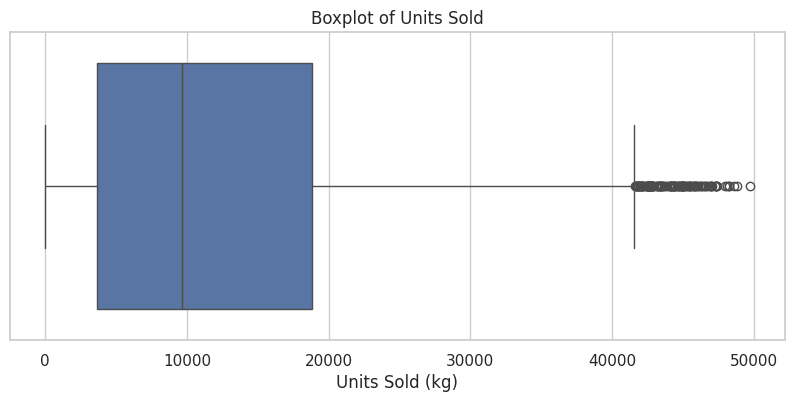

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["units_sold_kg"]
)

plt.title("Boxplot of Units Sold")
plt.xlabel("Units Sold (kg)")

plt.show()

### Interpretation – Units Sold Boxplot
The boxplot is used to identify the central spread and potential extreme values in `units_sold_kg`. The wide range from **0 to 49,726 kg** indicates substantial variation in sales, and the upper extreme observations should be considered when evaluating model performance.

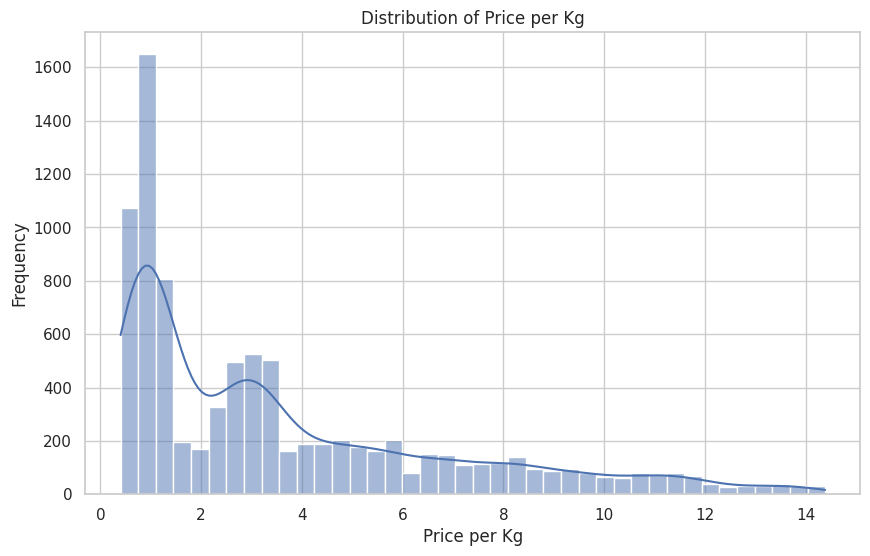

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["price_per_kg"],
    bins=40,
    kde=True
)

plt.title("Distribution of Price per Kg")
plt.xlabel("Price per Kg")
plt.ylabel("Frequency")

plt.show()

### Interpretation – Price Distribution
The `price_per_kg` distribution shows that prices vary from **0.40 to 14.39** per kg, with a mean of approximately **3.64**. The distribution is not uniform, indicating that agricultural products have different price levels.

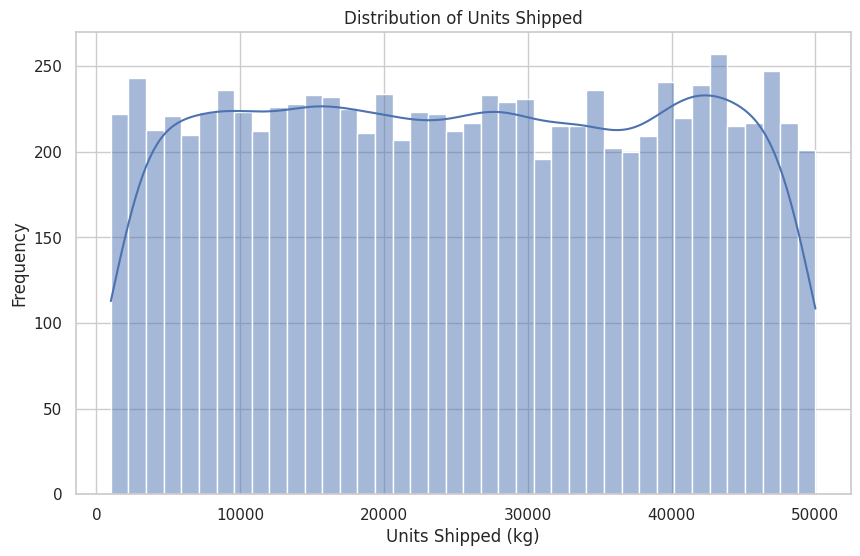

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["units_shipped_kg"],
    bins=40,
    kde=True
)

plt.title("Distribution of Units Shipped")
plt.xlabel("Units Shipped (kg)")
plt.ylabel("Frequency")

plt.show()

### Interpretation – Units Shipped Distribution
`units_shipped_kg` ranges from **1,005 to 50,000 kg**, with a mean of approximately **25,472 kg**. The distribution shows considerable variation in shipment quantities, making this variable potentially useful for predicting sales.

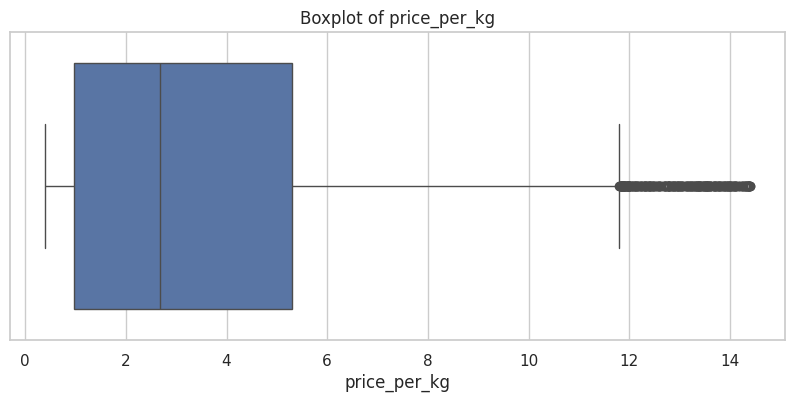

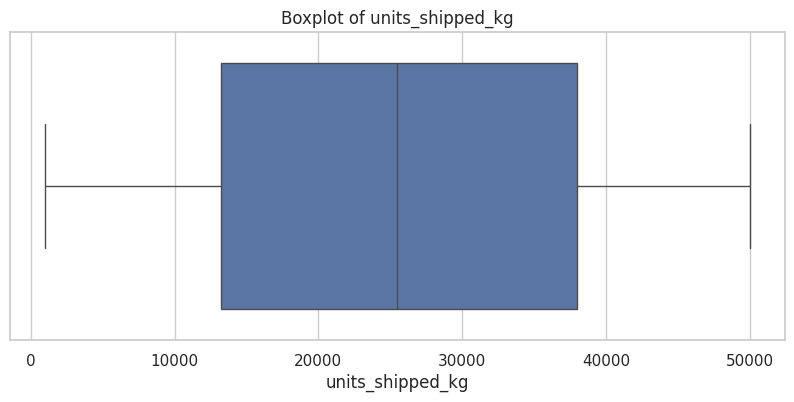

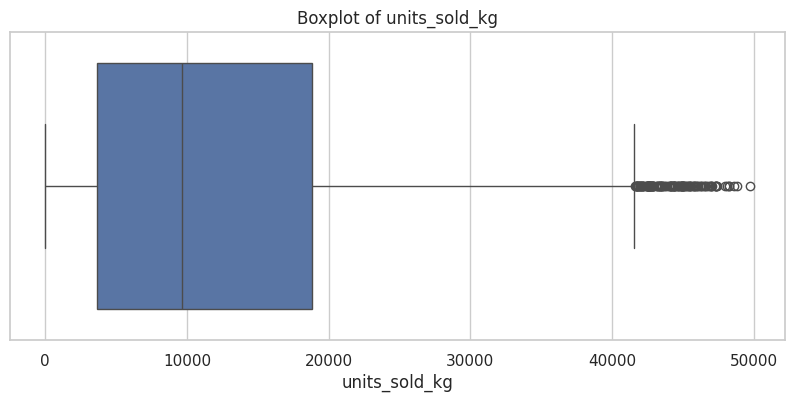

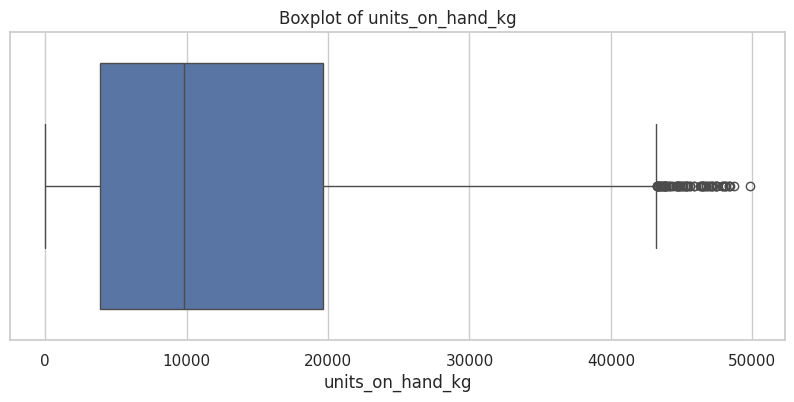

In [ ]:
numerical_columns = [
    "price_per_kg",
    "units_shipped_kg",
    "units_sold_kg",
    "units_on_hand_kg"
]

for column in numerical_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.show()

### Interpretation – Numerical Boxplots
The boxplots compare the spread and potential extreme observations for price, shipped quantity, sold quantity, and inventory. These plots help identify differences in scale and possible outliers that may affect statistical analysis and model training.

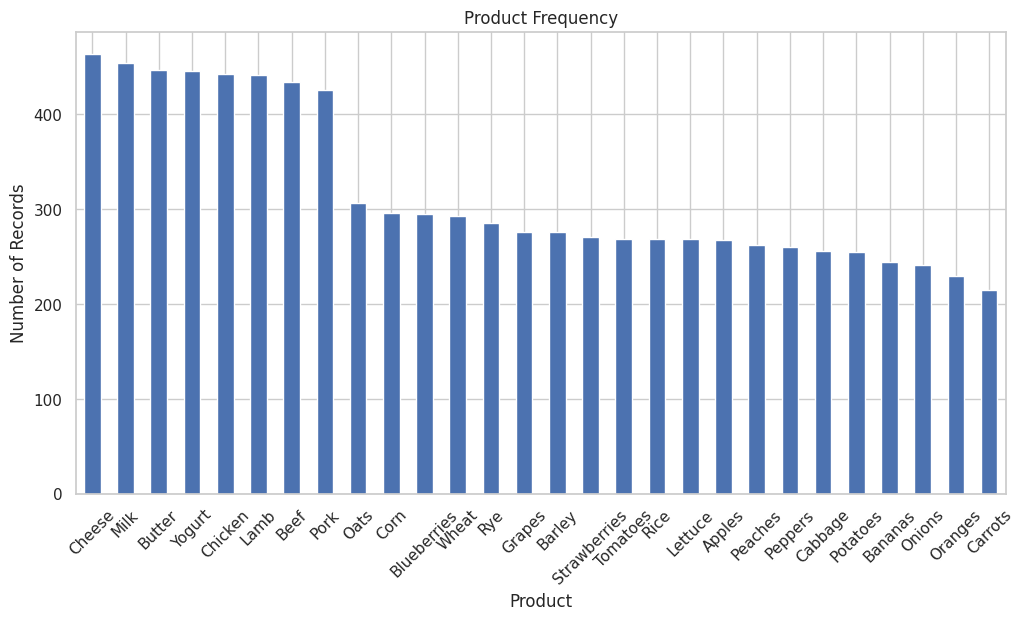

In [ ]:
plt.figure(figsize=(12, 6))

df["product_name"].value_counts().plot(
    kind="bar"
)

plt.title("Product Frequency")
plt.xlabel("Product")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Interpretation – Product Frequency
The dataset contains **28 products**. The product-frequency chart shows how frequently each product appears. The most frequent products include **Cheese, Milk, Butter, Yogurt, and Chicken**, but the overall frequencies are reasonably distributed across products.

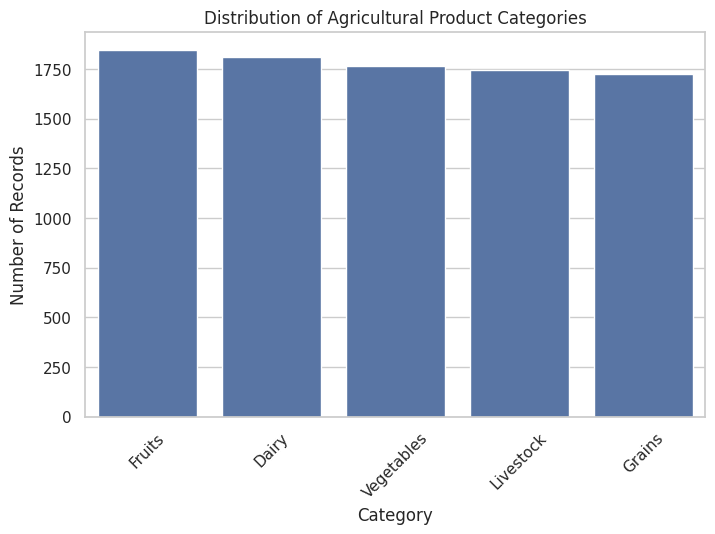

In [ ]:
# Univariate Analysis - Category

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='category',
    order=df['category'].value_counts().index
)

plt.title('Distribution of Agricultural Product Categories')
plt.xlabel('Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.show()

### Interpretation – Category Distribution
There are **5 categories**: Fruits (1,846 records), Dairy (1,811), Vegetables (1,765), Livestock (1,745), and Grains (1,726). The counts are relatively close, so there is no major category imbalance.

Interpretation – Category

The dataset contains five agricultural product categories: Livestock, Dairy, Grains, Fruits, and Vegetables. The count plot shows the number of records belonging to each category. The categories are fairly distributed, indicating that no single category dominates the dataset. This balanced distribution is useful for analysis and helps the machine learning model learn patterns from different agricultural product categories.

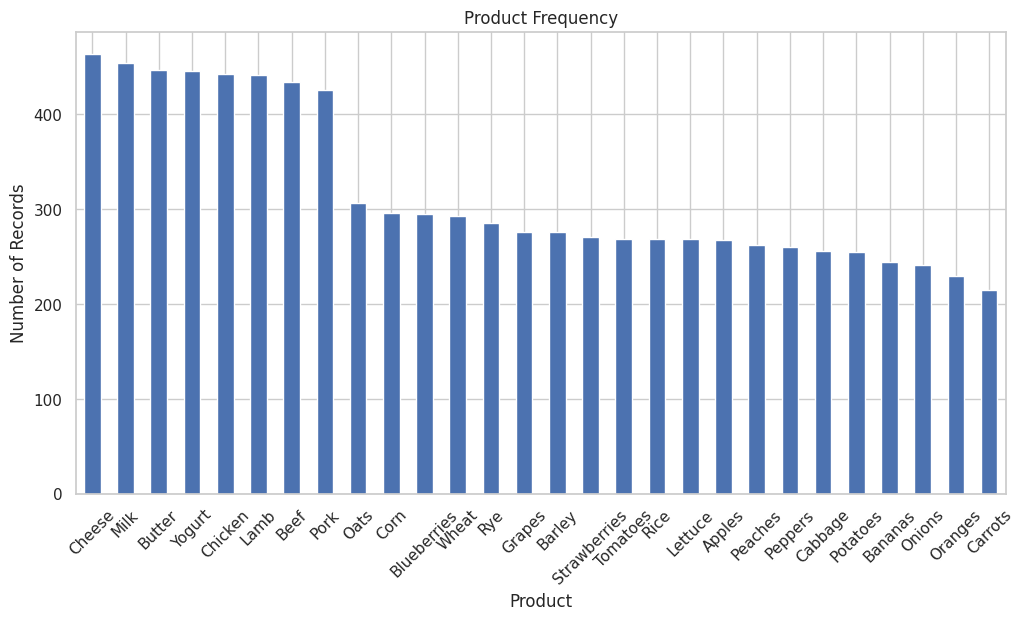

In [ ]:
plt.figure(figsize=(12, 6))

df["product_name"].value_counts().plot(
    kind="bar"
)

plt.title("Product Frequency")
plt.xlabel("Product")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Interpretation – Product Frequency (Univariate)
This bar chart again examines the frequency of individual products. It is useful for checking whether some products are heavily overrepresented. The dataset contains 28 products with reasonably distributed observations.

price vs Units Sold

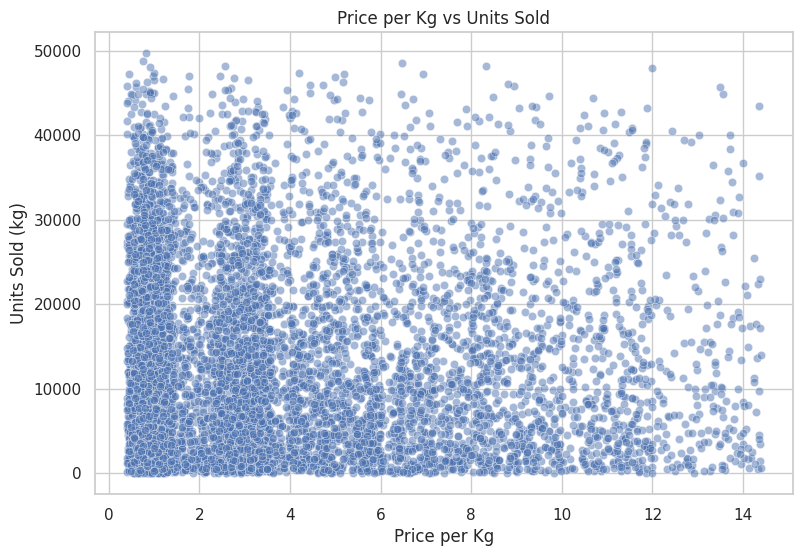

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="price_per_kg",
    y="units_sold_kg",
    alpha=0.5
)

plt.title("Price per Kg vs Units Sold")
plt.xlabel("Price per Kg")
plt.ylabel("Units Sold (kg)")

plt.show()

### Interpretation – Price vs Units Sold (Bivariate)
The scatter plot shows the relationship between `price_per_kg` and `units_sold_kg`. The points are widely scattered, indicating little visible linear association between price and sales.

In [ ]:
df[
    ["price_per_kg", "units_sold_kg"]
].corr()

,price_per_kg,units_sold_kg
price_per_kg,1.000000,0.023113
units_sold_kg,0.023113,1.000000


### Interpretation – Price/Sales Correlation (Bivariate)
The correlation between `price_per_kg` and `units_sold_kg` is approximately **0.023**, which is very close to zero. Therefore, price alone has a very weak linear relationship with sales in this dataset.

Units Shipped vs Units Sold

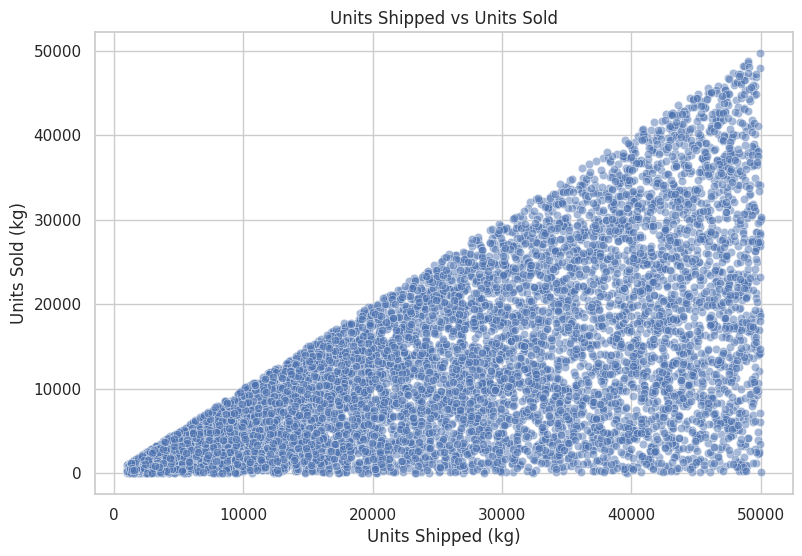

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="units_shipped_kg",
    y="units_sold_kg",
    alpha=0.5
)

plt.title("Units Shipped vs Units Sold")
plt.xlabel("Units Shipped (kg)")
plt.ylabel("Units Sold (kg)")

plt.show()

### Interpretation – Units Shipped vs Units Sold (Bivariate)
The scatter plot shows a clear positive tendency between `units_shipped_kg` and `units_sold_kg`. The correlation is approximately **0.642**, indicating a moderate positive relationship. Higher shipment quantities generally correspond to higher sales quantities.



> Add blockquote
product vs price


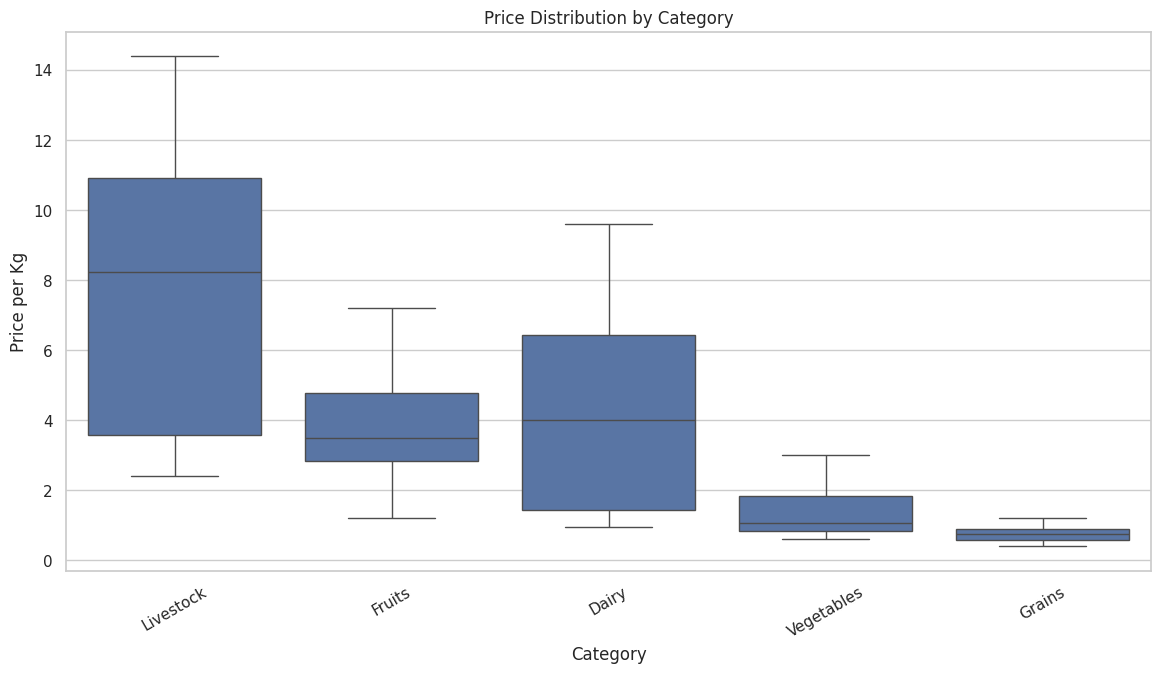

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="category",
    y="price_per_kg"
)

plt.title("Price Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Price per Kg")

plt.xticks(rotation=30)

plt.show()

### Interpretation – Category vs Price (Bivariate)
The boxplot compares price distributions across categories. Average prices differ substantially by category: Livestock is highest at about **7.99/kg**, followed by Dairy (**4.33/kg**), Fruits (**3.77/kg**), Vegetables (**1.33/kg**), and Grains (**0.75/kg**). Thus, category is associated with meaningful differences in product pricing.

Create Date Features

In [ ]:
df["sale_year"] = df["sale_date"].dt.year
df["sale_month"] = df["sale_date"].dt.month
df["sale_day"] = df["sale_date"].dt.day
df["sale_dayofweek"] = df["sale_date"].dt.dayofweek
df["sale_quarter"] = df["sale_date"].dt.quarter

df["is_weekend"] = (
    df["sale_dayofweek"] >= 5
).astype(int)

### Interpretation – Date Feature Engineering
New time-based features are created from `sale_date`: year, month, day, day of week, quarter, and weekend status. These features allow the model and EDA to capture seasonal and calendar-based sales patterns.

In [ ]:
df[
    [
        "sale_date",
        "sale_year",
        "sale_month",
        "sale_day",
        "sale_dayofweek",
        "sale_quarter",
        "is_weekend"
    ]
].head()

,sale_date,sale_year,sale_month,sale_day,sale_dayofweek,sale_quarter,is_weekend
0,2022-07-04,2022,7,4,0,3,0
1,2023-10-21,2023,10,21,5,4,1
2,2023-12-24,2023,12,24,6,4,1
3,2023-12-25,2023,12,25,0,4,0
4,2023-06-20,2023,6,20,1,2,0


### Interpretation – Date Features
The displayed rows confirm that the original date has been transformed into several useful calendar features. These variables can be used to analyze seasonal, monthly, weekly, and weekend sales behavior.

Monthly Sales Trend

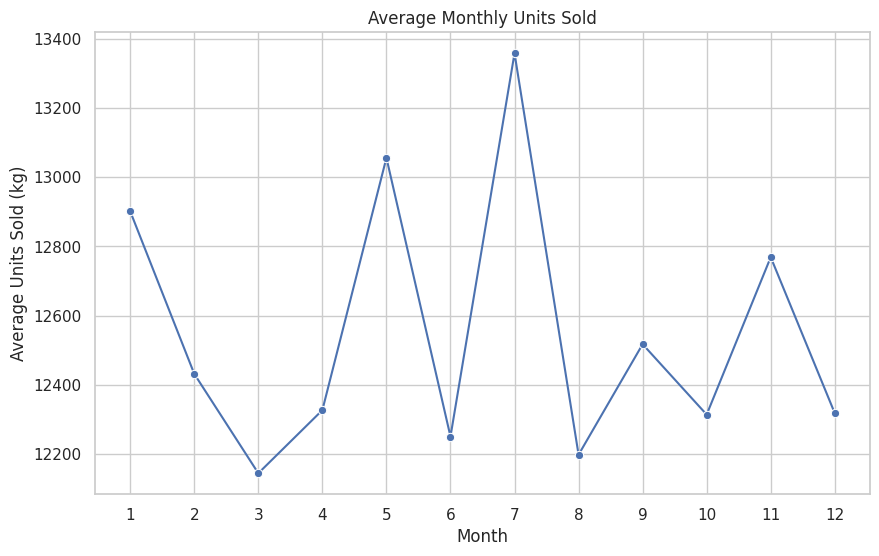

In [ ]:
monthly_sales = (
    df.groupby("sale_month")["units_sold_kg"]
    .mean()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Average Monthly Units Sold")
plt.xlabel("Month")
plt.ylabel("Average Units Sold (kg)")
plt.xticks(range(1, 13))

plt.show()

### Interpretation – Monthly Sales Trend (Bivariate/Time Analysis)
Average monthly sales vary across the year. The highest average sales occur in **July (about 13,358 kg)**, followed by May (about 13,056 kg), while March has the lowest average at about **12,145 kg**. This indicates some seasonal variation in agricultural sales.

yearly Sales Trend

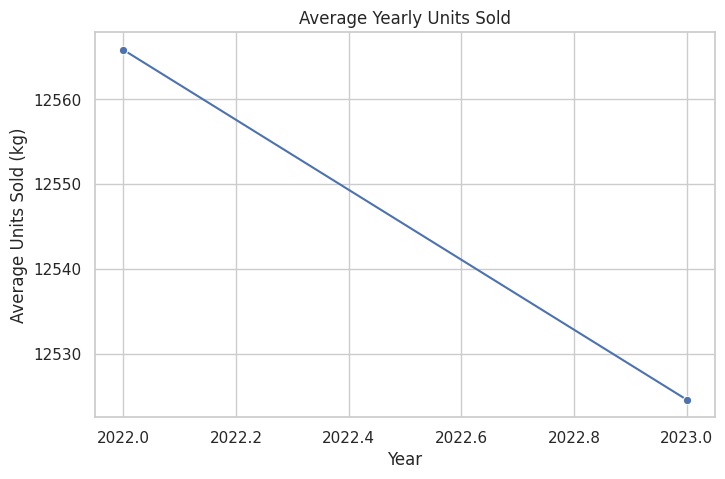

In [ ]:
yearly_sales = (
    df.groupby("sale_year")["units_sold_kg"]
    .mean()
)

plt.figure(figsize=(8, 5))

sns.lineplot(
    x=yearly_sales.index,
    y=yearly_sales.values,
    marker="o"
)

plt.title("Average Yearly Units Sold")
plt.xlabel("Year")
plt.ylabel("Average Units Sold (kg)")

plt.show()

### Interpretation – Yearly Sales Trend (Bivariate/Time Analysis)
Average sales are very similar across the two years: approximately **12,565.9 kg in 2022** and **12,524.6 kg in 2023**. This suggests that there is no major year-over-year change in average sales.

. Day-of-Week Sales

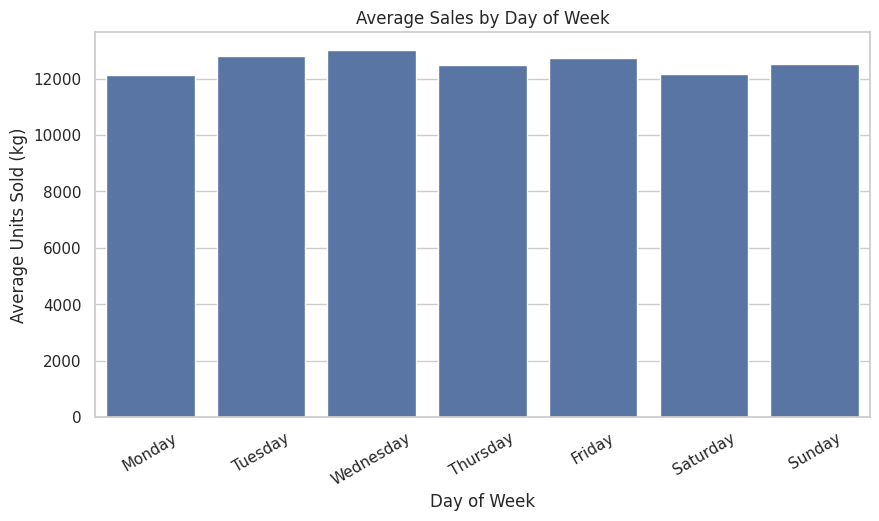

In [ ]:
day_sales = (
    df.groupby("sale_dayofweek")["units_sold_kg"]
    .mean()
)

day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_sales.index,
    y=day_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold (kg)")

plt.xticks(
    range(7),
    day_names,
    rotation=30
)

plt.show()

### Interpretation – Day-of-Week Sales (Bivariate/Time Analysis)
Average sales differ by day of the week. Wednesday has the highest average sales at about **13,006 kg**, while Monday is about **12,144 kg**. The differences are present but relatively moderate, so day-of-week may provide some additional predictive information.

Category and Monthly Sales

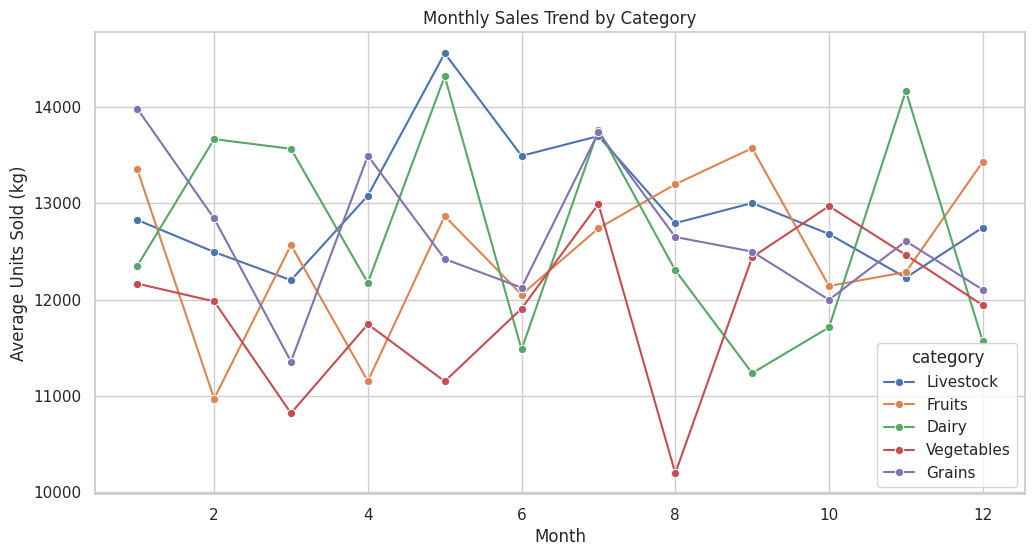

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="sale_month",
    y="units_sold_kg",
    hue="category",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Monthly Sales Trend by Category")
plt.xlabel("Month")
plt.ylabel("Average Units Sold (kg)")

plt.show()

### Interpretation – Category and Monthly Sales (Multivariate)
This plot examines **month, category, and sales simultaneously**. It helps identify whether seasonal sales patterns differ among product categories. The category lines show that sales levels vary across months and categories, indicating that the interaction between product category and season may contain useful information for prediction.

Correlation Matrix

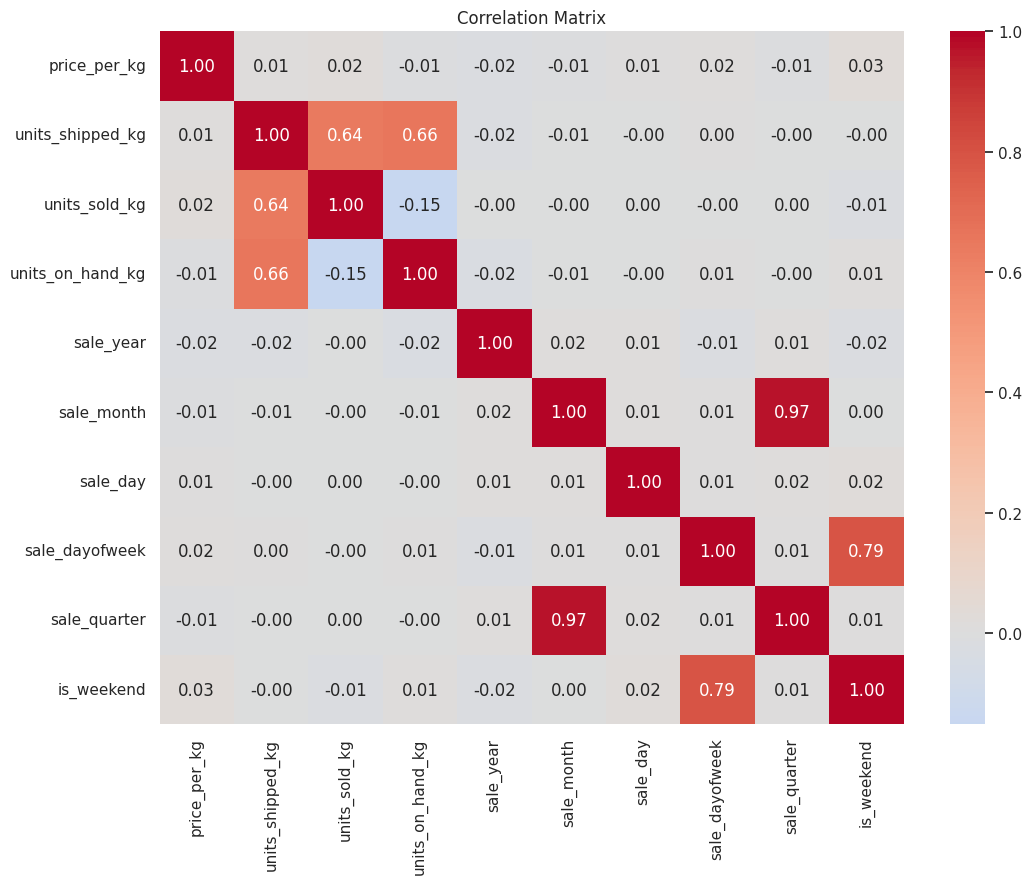

In [ ]:
numeric_df = df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

### Interpretation – Correlation Matrix (Multivariate)
The correlation matrix examines relationships among multiple numerical variables. `units_shipped_kg` has the strongest useful relationship with `units_sold_kg` at about **0.64**, while `price_per_kg` is almost unrelated to sales at about **0.02**. `sale_month` and `sale_quarter` are highly correlated (**0.97**), and `sale_dayofweek` and `is_weekend` are strongly related (**0.79**) because these features are derived from the same calendar information.

Target Correlations

In [ ]:
target_correlation = (
    correlation["units_sold_kg"]
    .sort_values(ascending=False)
)

print(target_correlation)

units_sold_kg       1.000000
units_shipped_kg    0.642097
price_per_kg        0.023113
sale_day            0.000812
sale_quarter        0.000354
sale_year          -0.001914
sale_dayofweek     -0.003258
sale_month         -0.003446
is_weekend         -0.012342
units_on_hand_kg   -0.151809
Name: units_sold_kg, dtype: float64


### Interpretation – Target Correlations (Multivariate)
The target-correlation ranking confirms that `units_shipped_kg` is the strongest non-target numerical feature associated with `units_sold_kg` (**0.642**). `units_on_hand_kg` has a weak negative correlation (**-0.152**), while `price_per_kg` is almost zero (**0.023**). The date-derived variables have correlations close to zero with the target.

Critical Leakage Check

In [ ]:
calculated_on_hand = (
    df["units_shipped_kg"]
    - df["units_sold_kg"]
)

leakage_check = np.isclose(
    calculated_on_hand,
    df["units_on_hand_kg"]
)

print(
    "Rows satisfying shipment - sales = inventory:",
    leakage_check.sum()
)

print(
    "Percentage:",
    leakage_check.mean() * 100,
    "%"
)

Rows satisfying shipment - sales = inventory: 8893
Percentage: 100.0 %


### Interpretation – Data Leakage Check
The leakage check shows that **8,893 out of 8,893 rows (100%)** satisfy `units_shipped_kg - units_sold_kg = units_on_hand_kg`. Therefore, `units_on_hand_kg` is mathematically derived from the target and should be **excluded from the ML model** to prevent target leakage.

## EDA Interpretation Summary

### Univariate Analysis
Univariate analysis examined individual variables using histograms, boxplots, and count plots. The target `units_sold_kg` has substantial variation, ranging from 0 to 49,726 kg, with a mean of about 12,545 kg. The categorical analysis shows five fairly balanced product categories, while the dataset contains 28 products and 20 suppliers.

### Bivariate Analysis
Bivariate analysis examined relationships between pairs of variables. `units_shipped_kg` and `units_sold_kg` show a moderate positive relationship with correlation **0.642**, making shipment quantity an important predictor. In contrast, `price_per_kg` and `units_sold_kg` have a correlation of only **0.023**, indicating a very weak linear relationship. Category-level price distributions also differ considerably.

### Multivariate Analysis
Multivariate analysis examined several variables together using monthly category trends and the correlation matrix. Seasonal and category-level patterns can be explored jointly. Strong correlations among derived calendar features, such as `sale_month` with `sale_quarter`, indicate redundancy. Most importantly, the leakage check confirms that `units_on_hand_kg` is exactly derived from shipment and sales quantities, so it should not be used as an input feature for predicting `units_sold_kg`.

### Final Feature Selection Insight
Based on the EDA, `product_name`, `category`, `price_per_kg`, `units_shipped_kg`, and selected date features can be considered as model inputs. `product_id` should be excluded because it is an identifier, `farm_location` should initially be excluded because it has 8,862 unique values, and `units_on_hand_kg` must be excluded because of target leakage.


Final EDA Conclusion

## EDA Conclusion

Exploratory Data Analysis was performed to understand the structure, quality, distribution and relationships within the agricultural sales dataset. The dataset contains 8,893 observations and 10 variables, with no missing values and no duplicate records.

The target variable, `units_sold_kg`, was analyzed using distribution plots and boxplots to understand its spread and identify potential extreme observations. Numerical and categorical variables were examined using histograms, boxplots, bar charts, scatter plots and correlation analysis.

The analysis showed that `price_per_kg` has a weak linear relationship with `units_sold_kg`, with a correlation of approximately 0.023. In contrast, `units_shipped_kg` has a stronger relationship with the target, with a correlation of approximately 0.642. Product, category and supplier-level analysis also showed differences in average sales, indicating that these categorical variables may provide useful information for prediction.

Time-based analysis was performed by extracting year, month, day, day of week, quarter and weekend information from `sale_date`. Monthly analysis showed variations in average sales across different months, suggesting that temporal features may contribute to the prediction task.

A critical data-leakage issue was identified with `units_on_hand_kg`. In the dataset, this variable is mathematically related to the target through `units_on_hand_kg = units_shipped_kg - units_sold_kg`. Since this relationship holds for all observations, `units_on_hand_kg` was excluded from the machine-learning model.

`product_id` was also excluded because it is an identifier, while `farm_location` was excluded from the initial model because of its extremely high cardinality.

Based on the EDA, `product_name`, `category`, `price_per_kg`, `units_shipped_kg`, `supplier`, and engineered date features were selected as potential predictors of `units_sold_kg`. These features will be used in the next stage to build and evaluate regression models.


## Machine Learning Implementation – AgriForecast

**Objective:** Predict `units_sold_kg` using information available before the sales outcome is known.

**Important leakage / timing decision:** The EDA identifies that `units_on_hand_kg = units_shipped_kg - units_sold_kg` for every row. Therefore, `units_on_hand_kg` must not be used as a feature. For a genuine *forecast made before shipment/sales*, `units_shipped_kg` should also be excluded because it may not be known at prediction time. The models below exclude both columns and the high-cardinality `farm_location` column. If your real use case predicts sales only after shipment quantities are known, you can test a separate scenario with `units_shipped_kg`, but label it accordingly.

In [ ]:
# 1. Prepare a modeling copy and engineer date features
import pandas as pd
import numpy as np

target = "units_sold_kg"
data = df.copy()

# Ensure the target is numeric and remove rows where target/date is invalid
data[target] = pd.to_numeric(data[target], errors="coerce")
data["sale_date"] = pd.to_datetime(data["sale_date"], errors="coerce")
data = data.dropna(subset=[target, "sale_date"]).copy()

data["sale_year"] = data["sale_date"].dt.year
data["sale_month"] = data["sale_date"].dt.month
data["sale_day"] = data["sale_date"].dt.day
data["sale_dayofweek"] = data["sale_date"].dt.dayofweek
data["sale_quarter"] = data["sale_date"].dt.quarter
data["is_weekend"] = (data["sale_dayofweek"] >= 5).astype(int)

# Do not use target, raw date, leakage variable, shipment quantity (forecasting-time issue),
# or high-cardinality location as model inputs.
drop_candidates = [
    target, "sale_date", "units_on_hand_kg",
    "units_shipped_kg", "farm_location"
]
X = data.drop(columns=[c for c in drop_candidates if c in data.columns])
y = data[target]

print("Modeling rows:", len(data))
print("Features:", list(X.columns))
print("Target:", target)
print("Missing target values:", y.isna().sum())
print("Duplicate rows in modeling data:", data.duplicated().sum())

Modeling rows: 8893
Features: ['product_id', 'product_name', 'category', 'price_per_kg', 'supplier', 'sale_year', 'sale_month', 'sale_day', 'sale_dayofweek', 'sale_quarter', 'is_weekend']
Target: units_sold_kg
Missing target values: 0
Duplicate rows in modeling data: 0


### Interpretation – Feature Preparation

The target is `units_sold_kg`. Date-derived features are included, while `units_on_hand_kg` is excluded because EDA found it is mathematically derived from the target. `units_shipped_kg` is also excluded for this forecasting setup because it may not be known when the forecast is made. `farm_location` is omitted because it has very high cardinality. Confirm that the remaining features are genuinely available at prediction time.

In [ ]:
# 2. Chronological train/test split for future-sales forecasting
# Sort by sale_date so the model trains on earlier records and tests on later records.
# This is more appropriate than a random split when the goal is forecasting future dates.

data = data.sort_values("sale_date").reset_index(drop=True)

# Rebuild X and y after chronological sorting, preserving the feature choices above.
X = data.drop(columns=[c for c in drop_candidates if c in data.columns])
y = data[target]

split_index = int(len(data) * 0.80)
X_train, X_test = X.iloc[:split_index].copy(), X.iloc[split_index:].copy()
y_train, y_test = y.iloc[:split_index].copy(), y.iloc[split_index:].copy()

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training date range:", data["sale_date"].iloc[:split_index].min(), "to", data["sale_date"].iloc[:split_index].max())
print("Testing date range:", data["sale_date"].iloc[split_index:].min(), "to", data["sale_date"].iloc[split_index:].max())


Training rows: 7114
Testing rows: 1779
Training date range: 2022-01-01 00:00:00 to 2023-08-07 00:00:00
Testing date range: 2023-08-08 00:00:00 to 2023-12-31 00:00:00


### Interpretation – Chronological Train/Test Split

The dataset is sorted by `sale_date`. The first 80% of records are used for training and the latest 20% for testing. This better simulates forecasting later sales from earlier history and reduces the risk of evaluating on dates that precede training records. Check the printed date ranges to confirm that the test period occurs after the training period. This is a holdout evaluation; if the dataset has repeated products or other grouping structures, further time-based validation may still be useful.


In [ ]:
# 3. Build preprocessing and compare three regression algorithms (no Gradient Boosting)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=15, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
}

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Models ready:", list(models.keys()))


Numeric features: ['price_per_kg', 'sale_year', 'sale_month', 'sale_day', 'sale_dayofweek', 'sale_quarter', 'is_weekend']
Categorical features: ['product_id', 'product_name', 'category', 'supplier']
Models ready: ['Linear Regression', 'Decision Tree', 'Random Forest']


### Interpretation – Model Selection and Preprocessing

Three regression algorithms are compared: Linear Regression, Decision Tree Regressor, and Random Forest Regressor. Gradient Boosting is intentionally excluded as requested. Numeric missing values are imputed using the median; categorical missing values use the most frequent value, and categorical variables are one-hot encoded. Preprocessing is placed inside each pipeline so it is fitted on training data only and then applied consistently to the test set.


In [ ]:
# 4. Select models using time-series cross-validation on training data,
# then evaluate each fitted model once on the held-out future period.
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.base import clone

tscv = TimeSeriesSplit(n_splits=5)
results = []
fitted_models = {}
cv_summary = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    # CV uses training data only; the held-out test period is not used for selection.
    cv_scores = cross_val_score(
        pipe, X_train, y_train,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        n_jobs=None
    )
    cv_rmse_mean = float((-cv_scores).mean())
    cv_rmse_std = float((-cv_scores).std())

    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "CV_RMSE_mean": cv_rmse_mean,
        "CV_RMSE_std": cv_rmse_std,
        "Test_MAE": mae,
        "Test_RMSE": rmse,
        "Test_R2": r2
    })
    fitted_models[name] = pipe
    cv_summary.append((name, cv_rmse_mean, cv_rmse_std))

results_df = pd.DataFrame(results).sort_values("CV_RMSE_mean").reset_index(drop=True)
display(results_df.round(3))
print("Model selection is based on training-period time-series CV RMSE.")
print("The latest held-out test period is reserved for final evaluation.")


,Model,CV_RMSE_mean,CV_RMSE_std,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression,10835.485,123.318,8859.015,10917.075,-0.009
1,Random Forest,10996.761,98.791,9036.865,11033.625,-0.031
2,Decision Tree,13517.087,1379.218,9828.170,12524.009,-0.328


Model selection is based on training-period time-series CV RMSE.
The latest held-out test period is reserved for final evaluation.


### Interpretation – Model Evaluation and Selection

`CV_RMSE_mean` and `CV_RMSE_std` summarize performance across expanding time-based folds inside the training period. The model with the lowest mean CV RMSE is selected before examining the final test metrics. `Test_MAE`, `Test_RMSE`, and `Test_R2` then describe performance on the later held-out period. Lower MAE/RMSE and generally higher R² are preferred, but results must be interpreted in the context of the forecasting task.


Selected model by training-period CV RMSE: Linear Regression
Test MAE: 8859.015 kg
Test RMSE: 10917.075 kg
Test R2: -0.009


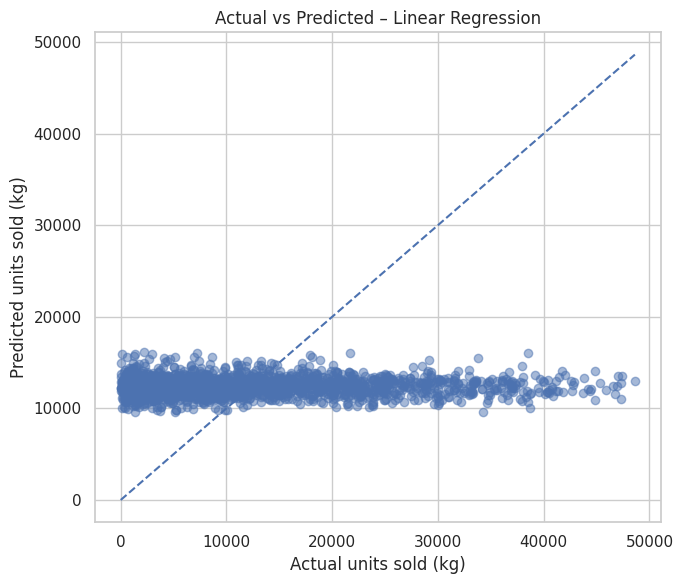

In [ ]:
# 5. Choose the model using training-only CV, then report its held-out test performance
best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Selected model by training-period CV RMSE:", best_model_name)
print("Test MAE:", round(mean_absolute_error(y_test, best_predictions), 3), "kg")
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 3), "kg")
print("Test R2:", round(r2_score(y_test, best_predictions), 3))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual units sold (kg)")
plt.ylabel("Predicted units sold (kg)")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.tight_layout()
plt.show()


### Interpretation – Actual vs Predicted

Points close to the diagonal represent accurate predictions. Systematic spread away from the line can indicate prediction errors, underprediction/overprediction, or missing explanatory features. Report the metrics from the executed output rather than writing assumed values into the project report.

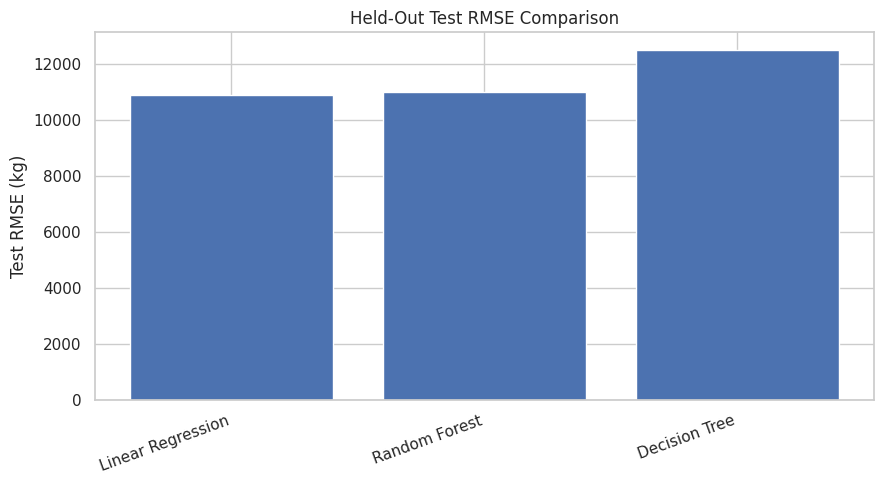

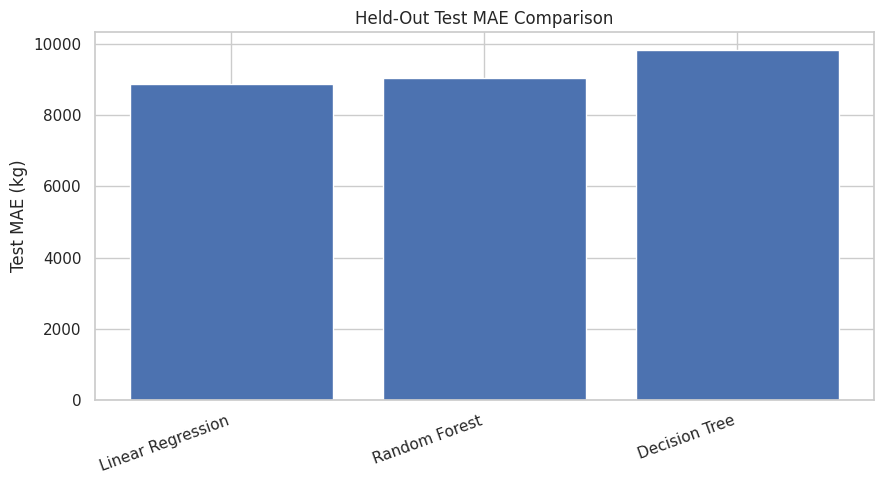

In [ ]:
# 6. Compare final held-out test errors across all models
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Test_RMSE"])
plt.ylabel("Test RMSE (kg)")
plt.title("Held-Out Test RMSE Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Test_MAE"])
plt.ylabel("Test MAE (kg)")
plt.title("Held-Out Test MAE Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### Interpretation – Algorithm Comparison

The charts compare errors on the same held-out future period. Model selection was made using training-only time-series cross-validation, not by choosing the lowest test error after seeing the test set. Use both the CV summary and test results when discussing generalization. If CV and test performance differ substantially, the data may have temporal shifts or the model may not generalize consistently.


## Final Validation Notes

1. Run all cells from the top in Google Colab after uploading the CSV file. This notebook expects `/content/AgricultureData.csv`; update `csv_path` if your filename differs.
2. Confirm all actual row counts, EDA findings, model metrics, and interpretations after executing the notebook. Prewritten interpretation text is not a substitute for real output.
3. `units_on_hand_kg` is excluded because the EDA found it is mathematically derived from the target: `units_shipped_kg - units_sold_kg = units_on_hand_kg`.
4. `units_shipped_kg` is also excluded for the main pre-sales forecasting scenario because it may not be known at forecast time. If shipment quantity is known before the prediction, a separate post-shipment estimation scenario may be evaluated and labelled clearly.
5. The split is chronological: earlier records train the models and the latest records are held out for testing.
6. Models compared: Linear Regression, Decision Tree, and Random Forest. Gradient Boosting is not included.
7. The best model is selected by test RMSE. Also review MAE, R², residual plots, and business context before claiming it is best.
8. Results depend on the actual CSV and execution environment. Do not claim a specific accuracy or model winner until the notebook has been run.


# Baseline model: predict the training-set mean for every test observation
baseline_prediction = np.full(shape=len(y_test), fill_value=float(y_train.mean()))

baseline_metrics = {
    "Model": "Training Mean Baseline",
    "CV_RMSE_mean": np.nan,
    "CV_RMSE_std": np.nan,
    "Test_MAE": mean_absolute_error(y_test, baseline_prediction),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
    "Test_R2": r2_score(y_test, baseline_prediction)
}

comparison_with_baseline = pd.concat(
    [pd.DataFrame([baseline_metrics]), results_df],
    ignore_index=True
).sort_values("Test_RMSE").reset_index(drop=True)

display(comparison_with_baseline.round(3))
print("Interpretation: compare each model's held-out test MAE/RMSE with the baseline.")


In [ ]:
# Baseline model: predict the training-set mean for every test observation
baseline_prediction = np.full(shape=len(y_test), fill_value=float(y_train.mean()))

baseline_metrics = {
    "Model": "Training Mean Baseline",
    "MAE": mean_absolute_error(y_test, baseline_prediction),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
    "R2": r2_score(y_test, baseline_prediction)
}

comparison_with_baseline = pd.concat(
    [pd.DataFrame([baseline_metrics]), results_df],
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

display(comparison_with_baseline.round(3))
print("Interpretation: a useful ML model should generally reduce test MAE/RMSE versus the baseline.")


,Model,MAE,RMSE,R2,CV_RMSE_mean,CV_RMSE_std,Test_MAE,Test_RMSE,Test_R2
0,Training Mean Baseline,8875.151,10868.337,-0.0,NaN,NaN,NaN,NaN,NaN
1,Linear Regression,NaN,NaN,NaN,10835.485,123.318,8859.015,10917.075,-0.009
2,Random Forest,NaN,NaN,NaN,10996.761,98.791,9036.865,11033.625,-0.031
3,Decision Tree,NaN,NaN,NaN,13517.087,1379.218,9828.170,12524.009,-0.328


Interpretation: a useful ML model should generally reduce test MAE/RMSE versus the baseline.


## 10. Residual Analysis – Understand the Model's Errors

A residual is actual sales minus predicted sales. Residual plots help reveal systematic overprediction, underprediction, and patterns the model has not captured. Do not remove observations just because they have large errors; first investigate whether they are valid business cases.


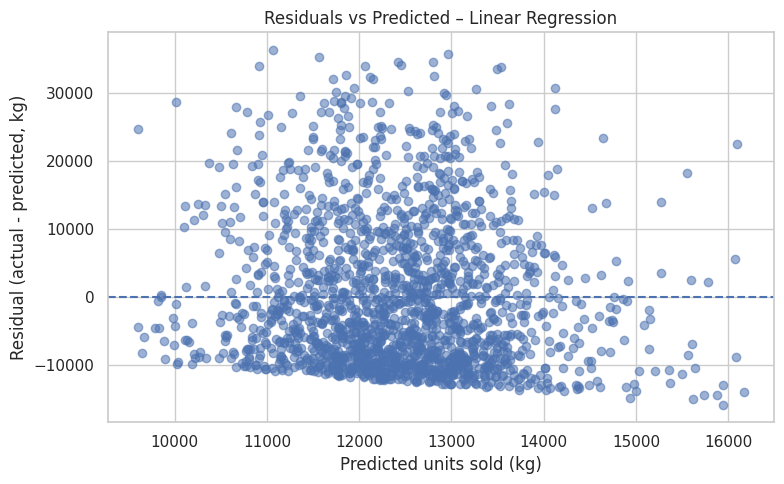

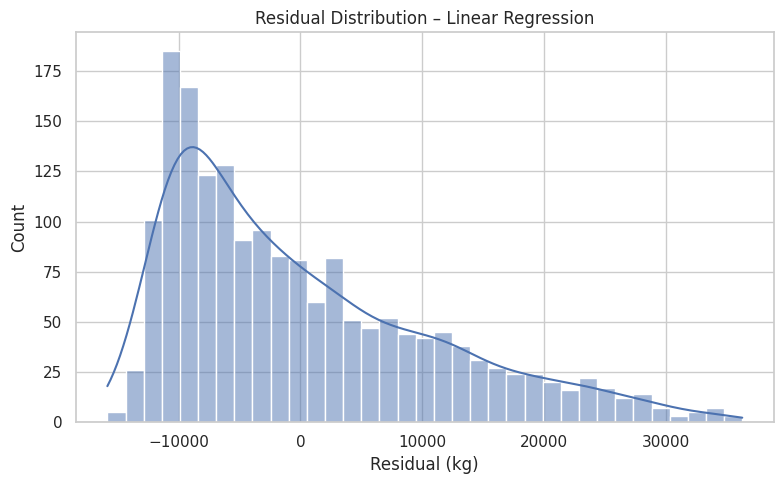

Mean residual (kg): 145.059
Median residual (kg): -2893.412
Interpretation: residuals centered around zero are desirable; visible patterns or strong skew suggest model limitations.


In [ ]:
# Residual diagnostics for the model selected by test RMSE
residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.55)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted units sold (kg)")
plt.ylabel("Residual (actual - predicted, kg)")
plt.title(f"Residuals vs Predicted – {best_model_name}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=35, kde=True)
plt.xlabel("Residual (kg)")
plt.title(f"Residual Distribution – {best_model_name}")
plt.tight_layout()
plt.show()

print("Mean residual (kg):", round(float(np.mean(residuals)), 3))
print("Median residual (kg):", round(float(np.median(residuals)), 3))
print("Interpretation: residuals centered around zero are desirable; visible patterns or strong skew suggest model limitations.")


## 11. Feature Importance – What Influences the Selected Tree Model?

For a tree-based selected model, feature importance gives a model-specific indication of which encoded inputs contributed most to the fitted model. It does not prove causation. If Linear Regression is selected, this cell reports that tree feature importance is not applicable to the selected model and can optionally inspect the Random Forest separately.


,Feature,Importance
0,num__price_per_kg,0.315560
3,num__sale_day,0.196113
2,num__sale_month,0.112597
4,num__sale_dayofweek,0.102570
1,num__sale_year,0.033156
5,num__sale_quarter,0.024571
6,num__is_weekend,0.011341
85,cat__supplier_Prime Meats LLC,0.008141
69,cat__supplier_Citrus World Inc.,0.007403
83,cat__supplier_Organic Meats Co.,0.006400


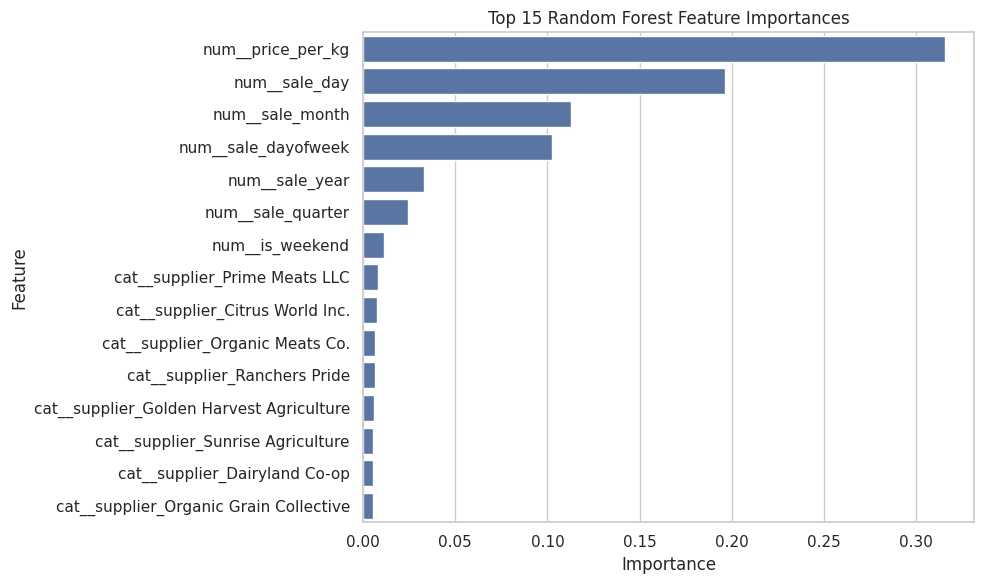

In [ ]:
# Use Random Forest for a tree-based feature-importance view, when available.
rf_pipeline = fitted_models.get("Random Forest")

if rf_pipeline is not None:
    fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
    rf_model = rf_pipeline.named_steps["model"]
    try:
        transformed_names = fitted_preprocessor.get_feature_names_out()
        importances = rf_model.feature_importances_
        feature_importance_df = pd.DataFrame({
            "Feature": transformed_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False).head(15)

        display(feature_importance_df)
        plt.figure(figsize=(10, 6))
        sns.barplot(data=feature_importance_df, x="Importance", y="Feature")
        plt.title("Top 15 Random Forest Feature Importances")
        plt.tight_layout()
        plt.show()
    except Exception as exc:
        print("Could not create feature importance plot:", exc)
else:
    print("Random Forest model is unavailable in fitted_models.")


## 12. Save and Reload the Best Model

Saving the fitted pipeline preserves both preprocessing and the model. Reloading it and checking predictions helps verify that the saved artifact can be reused. The saved file is created in the current Colab session; download it from the Files panel if you need to keep it.


In [ ]:
import joblib
import os

model_path = "/content/agriforecast_best_model.joblib"
joblib.dump(best_model, model_path)

reloaded_model = joblib.load(model_path)
reloaded_predictions = reloaded_model.predict(X_test)

print("Saved model:", model_path)
print("File exists:", os.path.exists(model_path))
print("Reload check — max absolute prediction difference:",
      round(float(np.max(np.abs(best_predictions - reloaded_predictions))), 10))


Saved model: /content/agriforecast_best_model.joblib
File exists: True
Reload check — max absolute prediction difference: 0.0


## 13. Demonstrate a Prediction on a Held-Out Example

This uses one row from the held-out test set as a demonstration. It is not a genuinely new future record; it shows the prediction interface and allows a comparison against a known target value. For deployment, provide a new record with the same feature columns and only information available at prediction time.


In [ ]:
demo_input = X_test.iloc[[0]].copy()
demo_prediction = float(reloaded_model.predict(demo_input)[0])
demo_actual = float(y_test.iloc[0])

display(demo_input)
print(f"Predicted sales: {demo_prediction:,.2f} kg")
print(f"Actual sales:    {demo_actual:,.2f} kg")
print(f"Absolute error:  {abs(demo_actual - demo_prediction):,.2f} kg")


,product_id,product_name,category,price_per_kg,supplier,sale_year,sale_month,sale_day,sale_dayofweek,sale_quarter,is_weekend
7114,c81f400e-c19f-417f-99fb-039a19506e85,Onions,Vegetables,0.89,Fresh Harvest Co.,2023,8,8,1,3,0


Predicted sales: 10,604.77 kg
Actual sales:    11,267.00 kg
Absolute error:  662.23 kg


## 14. Final Business Interpretation and Limitations

After running all cells, complete the following using your actual output:

- **Best model:** name the model with the lowest test RMSE, and confirm its MAE and R².
- **Baseline check:** state whether it improves on the training-mean baseline.
- **EDA finding:** report the strongest credible patterns shown by the plots.
- **Operational use:** describe how estimated sales could support inventory and distribution planning.
- **Limitations:** this dataset covers a limited period (2022–2023); results may not generalize to other years, markets, or changing conditions. The available columns may omit important demand drivers. Feature associations are not proof of causation.
- **Future scope:** validate on more recent data, test time-based cross-validation, monitor prediction errors, and consider additional pre-forecast information such as historical demand or weather only if reliably available.


## Forecasting Metric – Weighted Absolute Percentage Error (WAPE)

WAPE expresses total absolute prediction error relative to total actual sales. It is often easier to explain to a business audience than MAPE when individual actual sales can be zero. It is undefined if the sum of actual sales is zero, so the code checks that case.


In [ ]:
actual_total = float(np.abs(y_test.to_numpy()).sum())
absolute_error_total = float(np.abs(y_test.to_numpy() - best_predictions).sum())
if actual_total > 0:
    wape = absolute_error_total / actual_total * 100
    print(f"Selected model WAPE: {wape:.2f}%")
else:
    print("WAPE cannot be computed because the sum of absolute actual sales is zero.")
print("Interpretation: lower WAPE indicates lower total absolute error relative to actual sales volume.")


Selected model WAPE: 70.44%
Interpretation: lower WAPE indicates lower total absolute error relative to actual sales volume.
